In [1]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
load_dotenv()

C:\Users\sanke\AppData\Local\Temp\ipykernel_35296\1789131589.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries


True

In [2]:
# step 1 :
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
chunks = text_splitter.split_documents(raw_docs)

print(len(chunks))

51


In [3]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)
vectorstore.add_documents(chunks)

C:\Users\sanke\AppData\Local\Temp\ipykernel_35296\4132712200.py:5: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(


['e719bedc-9076-4ebb-ae11-9c8719c3fad0',
 '9a3b589e-29f5-4561-ac26-edc6b8663176',
 '7040ecfe-1a33-4c17-b0f1-5cb6ab8db5f9',
 'd1f1f353-7869-4d0a-8654-a7b87280a15a',
 '1d5733a2-89d0-4dd9-a8a4-90dfdf52ff75',
 '9fe216c5-f012-4621-9926-a7fc8f8aa549',
 '4f4bca8d-0b37-42b9-a56e-dd5cfe4910c5',
 'b13504cf-d0b2-4c59-9704-57afa8c861bf',
 '4d88cafd-a147-4772-8053-702b6361cab8',
 'd35de056-e90d-435b-aafe-81730945a3c4',
 '4a4be7de-8b34-46e0-af3e-24647c9cae38',
 '0f316f50-ff94-40cf-b717-4f06ec302703',
 'd7d3e3d9-ce9e-4c08-8714-33ac372bddd7',
 '4bcd48f5-d589-495d-9896-c7171af9903b',
 '91161aa8-4fd5-4a25-973f-8443a1790c56',
 '1ec5e919-3ea1-493b-aab0-11be73d5f590',
 '9e600a14-434f-41f4-9c22-a535c90d1fc4',
 '240299e9-a3aa-4352-9662-d6d149a13b47',
 'b10c5f8c-2f77-4930-9c51-27f40e16cf49',
 '43716bca-6de3-450a-a097-86dace49497a',
 '16cc4fe7-ee3b-44fc-b241-e25fa28fa99e',
 '6980eb38-5b4e-44cc-a7c0-cc46015c1119',
 '5f26ddf1-cbd1-4907-b863-c1801520b928',
 '76ed87e8-304d-4a54-a40c-af7108dd6ec7',
 '91049519-9ba7-

In [4]:
# step 4 : retrieval

retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [5]:
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str | None
    generation: str
    needs_retrieval: bool


llm = ChatOpenAI(model="gpt-5-mini")

In [6]:
class RouteDecision(BaseModel):
    needs_retrieval: bool

In [7]:
def route_question(state: AgenticRAGState):
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    return {"needs_retrieval": decision.needs_retrieval}


def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    if docs:
        context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context}



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": context})
        return {"generation": response}
    else:
        print('inside else part')
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": None})
        return {"generation": response}

In [8]:
from typing import Literal

def route_after_classification(state: AgenticRAGState) -> Literal["retrieve", "generate"]:
    return "retrieve" if state['needs_retrieval'] else "generate"

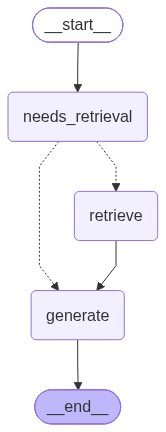

In [9]:
graph_builder = StateGraph(AgenticRAGState)
graph_builder.add_node("needs_retrieval", route_question)
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "needs_retrieval")
graph_builder.add_conditional_edges("needs_retrieval", route_after_classification)
graph_builder.add_edge("retrieve", "generate")

graph_builder.add_edge("generate", END)
graph = graph_builder.compile()
graph

In [10]:
# Query 1: domain-specific (should trigger retrieval)
domain_query = "What does the report say about EV adoption trajectories and oil demand displacement?"

result_domain = graph.invoke({"query": domain_query, "messages": []})

In [11]:
result_domain

{'messages': [],
 'query': 'What does the report say about EV adoption trajectories and oil demand displacement?',
 'retrieved_docs': [Document(metadata={'total_pages': 15, 'page_label': '8', 'source': './documents/evs_oil_price_shock.pdf', 'creator': '(unspecified)', 'moddate': '2026-04-18T21:49:03+05:00', 'title': '(anonymous)', 'page': 7, 'trapped': '/False', 'subject': '(unspecified)', 'creationdate': '2026-04-18T21:49:03+05:00', 'producer': 'ReportLab PDF Library - (opensource)', 'keywords': '', 'author': '(anonymous)'}, page_content='Will EVs Dampen the Oil Price Shock?\nVersion 1.0\nResearch Report — For Educational and RAG Pipeline Use\nPage 8\n4. EV Adoption Trajectories and Oil Demand Displacement\n Projecting oil demand displacement from EV adoption requires integrating three distinct\nanalytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing\nICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.\nTh

In [12]:
general_query = "What is the capital of India?"
result_general = graph.invoke({"query": general_query, "messages": [], "context": None})

inside else part


In [13]:
result_general

{'messages': [],
 'query': 'What is the capital of India?',
 'context': None,
 'generation': 'The capital of India is New Delhi.',
 'needs_retrieval': False}

In [ ]:
#route_question(AgenticRAGState(query="who is prime minimiser of India"))

{'needs_retrieval': False}

In [15]:
llm.invoke('tell me today top 5 news')

AIMessage(content='I can’t fetch live headlines right now. Do you want me to:\n\n- Look up today’s top 5 stories for a specific region (global, US, UK, EU, India, etc.) or topic (world, politics, tech, business, sports, science)? — tell me which and I’ll fetch/summarize if you paste links or allow me to use a browsing tool; or\n- Give a quick rundown of where to find top stories now (recommended sources and how to view “Top stories”) and how I’ll format a summary if you want it?\n\nIf you tell me the region/topic and whether you want brief headlines or short summaries, I’ll proceed.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 595, 'prompt_tokens': 13, 'total_tokens': 608, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 448, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens